# Végső projekt — előkészítés: szállodai foglalások lemondása

**Adat:** Hotel Booking Demand — két portugál szálloda (egy lisszaboni városi szálloda és egy algarvei üdülőszálloda) foglalásai, 2015 júliusa és 2017 augusztusa között érkezőkkel. Forrás: N. Antonio, A. de Almeida, L. Nunes (2019): *Hotel booking demand datasets*, Data in Brief 22, 41–49 (CC BY), a TidyTuesday-projekt CSV-változatában.

**Ez a notebook:** az adat bemutatása és a feltérképező elemzés (EDA). A modellezés a végső projekt része lesz.

## A kérdés

**Előre jelezhető-e, hogy egy foglalást le fognak mondani?** A célváltozó az `is_canceled` (1 = lemondta, vagy nem jelent meg). A probléma a bevételmenedzsmenté. Ha a szálloda tudja, mely foglalások valószínűleg maradnak el, **túlfoglalhat**, célzott emlékeztetőt vagy előleg-ajánlatot küldhet, és pontosabban tervezheti a személyzetet. Egy elmaradt foglalás üres szobát jelent, a túl agresszív túlfoglalás pedig vendégelhelyezési költséget és rossz élményt.

**Miért ez az adat (a három kritérium):**
1. **Elég megfigyelés:** 119 390 foglalás, a 20 ezres küszöb közel hatszorosa.
2. **Érdekel a probléma:** kereskedelem és marketing szakos hallgatóként a foglalási csatornák, az árazás és az ügyfélviselkedés kapcsolata közvetlenül a szakterületem. Az adat valódi szállodai rendszerből (PMS) származik.
3. **A magyarázó változók magyarázzák a célt:** az alábbi ábrákon a lemondási arány a magyarázó változók mentén **10% és 99% között** mozog. Egy első, hangolás nélküli modell is jóval veri a véletlent (a fejezet végén).

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100

# Adatforrás: Antonio, Almeida & Nunes (2019), Data in Brief 22; a TidyTuesday-féle CSV változat
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
raw = pd.read_csv("hotel_bookings.csv" if os.path.exists("hotel_bookings.csv") else URL, na_values=["NULL"])
df = raw.copy()

MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October",
          "November", "December"]
df["arrival_date"] = pd.to_datetime(dict(year=df["arrival_date_year"],
                                         month=df["arrival_date_month"].map({m: i + 1 for i, m in enumerate(MONTHS)}),
                                         day=df["arrival_date_day_of_month"]))
print("Sor × oszlop:", raw.shape)
print("Érkezések:", df["arrival_date"].min().date(), "–", df["arrival_date"].max().date())
print(f"Lemondási arány: {df['is_canceled'].mean():.1%}  ({df['is_canceled'].sum():,} / {len(df):,})")
df.head(3).T

Sor × oszlop: (119390, 32)
Érkezések: 2015-07-01 – 2017-08-31
Lemondási arány: 37.0%  (44,224 / 119,390)


,0,1,2
hotel,Resort Hotel,Resort Hotel,Resort Hotel
is_canceled,0,0,0
lead_time,342,737,7
arrival_date_year,2015,2015,2015
arrival_date_month,July,July,July
arrival_date_week_number,27,27,27
arrival_date_day_of_month,1,1,1
stays_in_weekend_nights,0,0,0
stays_in_week_nights,0,0,1
adults,2,2,1


**A változók (32 oszlop) csoportokban:**

| Csoport | Oszlopok | Mikor ismert? |
|---|---|---|
| Foglalás és időzítés | `lead_time` (a foglalás és az érkezés közti napok), az érkezés éve, hónapja, hete és napja | a foglaláskor |
| Tartózkodás | hétvégi és hétköznapi éjszakák, felnőttek, gyerekek, babák, ellátás (`meal`) | a foglaláskor |
| Csatorna és ügyfél | `market_segment`, `distribution_channel`, `agent`, `company`, `customer_type`, `country`, visszatérő vendég, korábbi (le nem mondott) foglalások és lemondások | a foglaláskor (az országnál kérdéses, lásd lent) |
| Ár és feltételek | `adr` (átlagos napi ár, €), `deposit_type` (előleg), foglalt szobatípus | a foglaláskor |
| Kérések és változások | különleges kérések, parkolóhely, `booking_changes`, várólistán töltött napok | részben később |
| **Kimenet (nem jellemző!)** | `reservation_status`, `reservation_status_date`, `assigned_room_type` | a lemondáskor vagy az érkezéskor |

## Adatminőség

In [2]:
# Hiányzó értékek
na = df.isna().sum()
na = na[na > 0].to_frame("hiányzó db").assign(arány=lambda t: (t["hiányzó db"] / len(df)).round(3))
display(na)
for c in ["agent", "company"]:
    print(f"Lemondási arány, ha a(z) {c} hiányzik: {df.loc[df[c].isna(), 'is_canceled'].mean():.1%}, ha megvan: {df.loc[df[c].notna(), 'is_canceled'].mean():.1%}")

,hiányzó db,arány
children,4,0.000
country,488,0.004
agent,16340,0.137
company,112593,0.943


Lemondási arány, ha a(z) agent hiányzik: 24.7%, ha megvan: 39.0%
Lemondási arány, ha a(z) company hiányzik: 38.2%, ha megvan: 17.5%


In [3]:
# Duplikátumok és furcsa értékek
dup = raw.duplicated()
print(f"Teljesen azonos sorok: {dup.sum():,} ({dup.mean():.1%}); lemondási arány köztük: {df.loc[dup, 'is_canceled'].mean():.1%}")
print("A duplikátumok szegmense:", df.loc[dup, "market_segment"].value_counts(normalize=True).round(2).head(4).to_dict())
print("A nem duplikált sorok szegmense:", df.loc[~dup, "market_segment"].value_counts(normalize=True).round(2).head(4).to_dict())
guests = df["adults"] + df["children"].fillna(0) + df["babies"]
nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
odd = pd.Series({
    "0 vendég": int((guests == 0).sum()),
    "0 éjszaka": int((nights == 0).sum()),
    "napi ár (adr) ≤ 0": int((df["adr"] <= 0).sum()),
    "napi ár (adr) < 0": int((df["adr"] < 0).sum()),
    "napi ár > 1000 €": int((df["adr"] > 1000).sum()),
    "napi ár maximuma (€)": float(df["adr"].max()),
})
odd.to_frame("db / érték")

Teljesen azonos sorok: 31,994 (26.8%); lemondási arány köztük: 63.1%
A duplikátumok szegmense: {'Groups': 0.46, 'Offline TA/TO': 0.32, 'Online TA': 0.15, 'Corporate': 0.03}
A nem duplikált sorok szegmense: {'Online TA': 0.59, 'Offline TA/TO': 0.16, 'Direct': 0.14, 'Groups': 0.06}


,db / érték
0 vendég,180.0
0 éjszaka,715.0
napi ár (adr) ≤ 0,1960.0
napi ár (adr) < 0,1.0
napi ár > 1000 €,1.0
napi ár maximuma (€),5400.0


**Hiányzó értékek. Mind a négy oszlopnál a hiánynak jelentése van:**
- **`company`** (94,3% hiányzik): a hiány azt jelenti, hogy „nem céges foglalás”. A céges foglalásoknak csak 17,5%-át mondják le, a többinek 38,2%-át. A hiány tehát **jel**, nem hiba.
- **`agent`** (13,7% hiányzik): a hiány „nem utazási irodán keresztül” foglalást jelent. Ezeknek 24,7%-át mondják le, az irodán keresztülieknek 39,0%-át.
- **`country`** (488 sor) és **`children`** (4 sor): elhanyagolható, „ismeretlen” kategória vagy 0 lesz.

**Duplikátumok: 31 994 sor (26,8%) teljesen azonos egy másikkal.** Ez sok. A duplikátumok 46%-a csoportos foglalás (a többi sornál csak 6%), és 63,1%-ukat lemondták. A legvalószínűbb magyarázat, hogy egy csoportos foglalás minden szobája külön sor, azonos adatokkal. **Döntés a végső projektre:** nem dobom el őket, mert valódi szobafoglalások. De **nem szakadhatnak szét** a tanító és a teszt között (a házáras házi „többször eladott házaihoz” hasonlóan), különben a modell „emlékszik” a csoport többi szobájára.

**Furcsa értékek:** 180 foglalásban nincs vendég, 715-ben 0 éjszaka szerepel (napközbeni használat?), 1 960-ban a napi ár 0 vagy negatív (ingyenes, „Complementary” szegmens), és egy 5 400 €-s napi ár egyértelmű elírás. Ezeket a végső projektben szűröm vagy jelölöm, mindegyiket indokolva.

## Feltérképező elemzés: mi függ össze a lemondással?

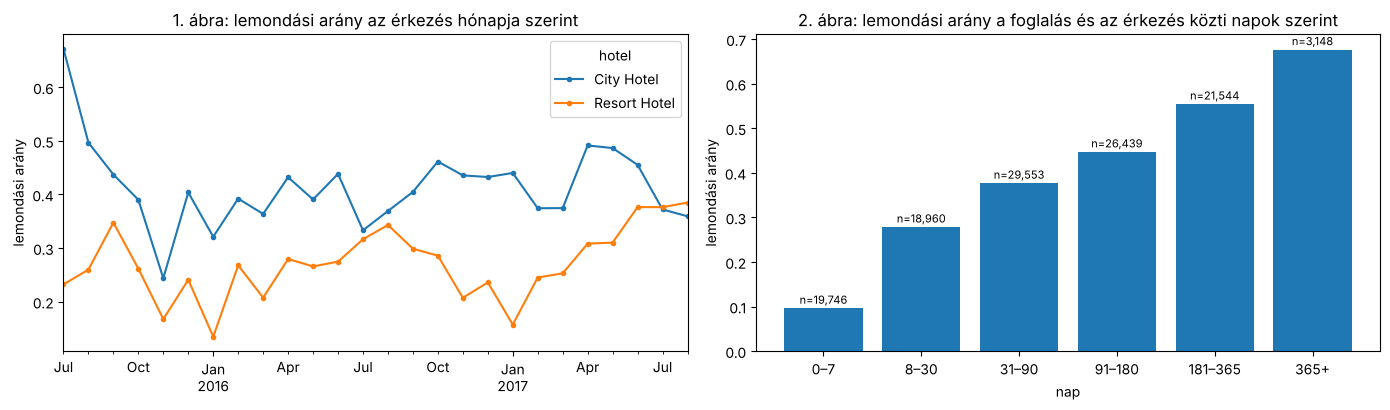

               mean   size
hotel                     
City Hotel    0.417  79330
Resort Hotel  0.278  40060


lead_time,0–7,8–30,31–90,91–180,181–365,365+
mean,0.096,0.279,0.377,0.447,0.555,0.677
size,19746.000,18960.000,29553.000,26439.000,21544.000,3148.000


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
# 1. ábra: lemondási arány havonta (érkezés szerint), szállodánként
m = df.set_index("arrival_date").groupby("hotel").resample("MS")["is_canceled"].mean().unstack(0)
m.plot(ax=ax[0], marker="o", ms=3)
ax[0].set(title="1. ábra: lemondási arány az érkezés hónapja szerint", ylabel="lemondási arány", xlabel="")
# 2. ábra: lemondási arány a foglalás előrehozása (lead time) szerint
bins = [-1, 7, 30, 90, 180, 365, 1000]
lab = ["0–7", "8–30", "31–90", "91–180", "181–365", "365+"]
lt = df.groupby(pd.cut(df["lead_time"], bins, labels=lab), observed=True)["is_canceled"].agg(["mean", "size"])
ax[1].bar(lt.index.astype(str), lt["mean"])
for i, (k, r) in enumerate(lt.iterrows()):
    ax[1].text(i, r["mean"] + 0.01, f"n={int(r['size']):,}", ha="center", fontsize=8)
ax[1].set(title="2. ábra: lemondási arány a foglalás és az érkezés közti napok szerint", xlabel="nap", ylabel="lemondási arány")
plt.tight_layout(); plt.show()
print(df.groupby("hotel")["is_canceled"].agg(["mean", "size"]).round(3))
lt.round(3).T

**1. ábra, idő és szálloda:**
- A városi szálloda foglalásainak **41,7%-át** mondják le, az üdülőszállodáénak **27,8%-át**.
- Mindkettőnél van szezonalitás, és 2015 nyarán a városi szálloda kiugró (az első hónapban kb. 67%).
- **Következmény:** az adat időrendi, tehát a végső modellt **időrendi vágással** kell mérni (a múltból a jövőre), és figyelni kell a sodródásra.

**2. ábra, a legerősebb egyedi jel:** minél korábban foglal valaki, annál valószínűbben mondja le. 0–7 nap előtt **9,6%**, 1 évnél korábban **67,7%**. Ez üzletileg is logikus: hosszú idő alatt sok minden változhat, és a korai foglalók gyakran „biztosítékként” foglalnak.

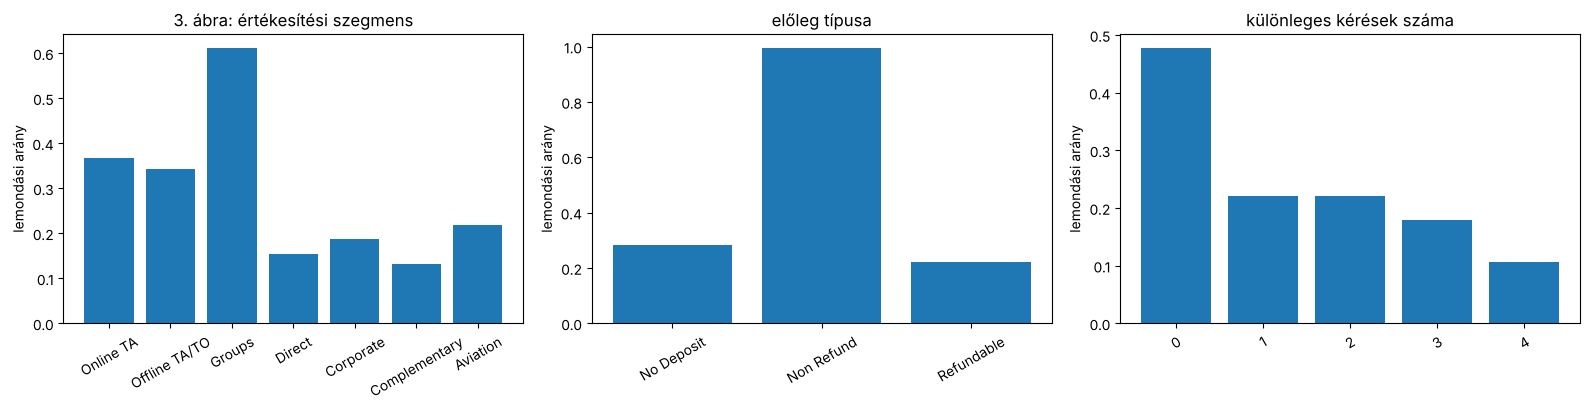

,arány,db
deposit_type,,
No Deposit,0.284,104641
Non Refund,0.994,14587
Refundable,0.222,162


,arány,db
market_segment,,
Online TA,0.367,56477
Offline TA/TO,0.343,24219
Groups,0.611,19811
Direct,0.153,12606
Corporate,0.187,5295
Complementary,0.131,743
Aviation,0.219,237
Undefined,1.000,2


In [5]:
def rate(col, top=None):
    g = df.groupby(col, observed=True)["is_canceled"].agg(arány="mean", db="size").sort_values("db", ascending=False)
    return (g.head(top) if top else g).round(3)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, col, title in [(ax[0], "market_segment", "3. ábra: értékesítési szegmens"),
                      (ax[1], "deposit_type", "előleg típusa"),
                      (ax[2], "total_of_special_requests", "különleges kérések száma")]:
    g = rate(col).sort_index() if col == "total_of_special_requests" else rate(col)
    g = g[g["db"] >= 100]
    a.bar(g.index.astype(str), g["arány"]); a.set(title=title, ylabel="lemondási arány")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
display(rate("deposit_type"), rate("market_segment"))

**3. ábra, csatorna, előleg, kérések:**
- **Szegmens:** a csoportos foglalások **61,1%-át** mondják le, a közvetlen (`Direct`) foglalásoknak csak **15,3%-át**, a céges foglalásoknak 18,7%-át.
- **Különleges kérések:** kérés nélkül 47,7% a lemondás, 1 kérésnél 22,0%, 4-nél 10,0%. Aki kér valamit (pl. kiságyat, emeletet), az komolyan tervez.
- **Előleg:** **a vissza nem térítendő előleggel (`Non Refund`) foglalt szobák 99,4%-át lemondják**, az előleg nélkülieknek 28,4%-át. Ez első ránézésre ellentmond a józan észnek, ezért közelebbről megnéztem.

In [6]:
# A „vissza nem térítendő előleg → 99% lemondás” furcsaság közelebbről
nr = df["deposit_type"] == "Non Refund"
comp = pd.DataFrame({
    "Non Refund": [nr.sum(), df.loc[nr, "hotel"].eq("City Hotel").mean(), df.loc[nr, "market_segment"].eq("Groups").mean(),
                   df.loc[nr, "distribution_channel"].eq("TA/TO").mean(), df.loc[nr, "lead_time"].median(),
                   df.loc[nr, "country"].eq("PRT").mean(), df.loc[nr, "is_repeated_guest"].mean()],
    "többi": [(~nr).sum(), df.loc[~nr, "hotel"].eq("City Hotel").mean(), df.loc[~nr, "market_segment"].eq("Groups").mean(),
              df.loc[~nr, "distribution_channel"].eq("TA/TO").mean(), df.loc[~nr, "lead_time"].median(),
              df.loc[~nr, "country"].eq("PRT").mean(), df.loc[~nr, "is_repeated_guest"].mean()]},
    index=["db", "városi szálloda", "csoportos szegmens", "utazási iroda (TA/TO)", "lead time medián (nap)", "portugál", "visszatérő vendég"])
comp.round(3)

,Non Refund,többi
db,14587.000,104803.000
városi szálloda,0.882,0.634
csoportos szegmens,0.629,0.102
utazási iroda (TA/TO),0.936,0.804
lead time medián (nap),183.000,57.000
portugál,0.972,0.328
visszatérő vendég,0.004,0.036


**A `Non Refund` furcsaság:** ezek a foglalások szinte mind ugyanabból a körből jönnek:
- 97,2%-uk portugál (a többinél 32,8%), 88,2%-uk a városi szállodába szól;
- 62,9%-uk csoportos (a többinél 10,2%), 93,6%-uk utazási irodán keresztül érkezik;
- a medián előrehozásuk 183 nap (a többinél 57 nap).

A valószínű magyarázat: **utazási irodák előre lefoglalt szobakontingensei**, amelyeket később „visszaadnak”. Ez nem a klasszikus értelemben vett vendég-lemondás. **Kérdés a visszajelzéshez:** a végső projektben ezt a csoportot külön kezeljem (vagy zárjam ki), vagy maradjon benne jellemzőként?

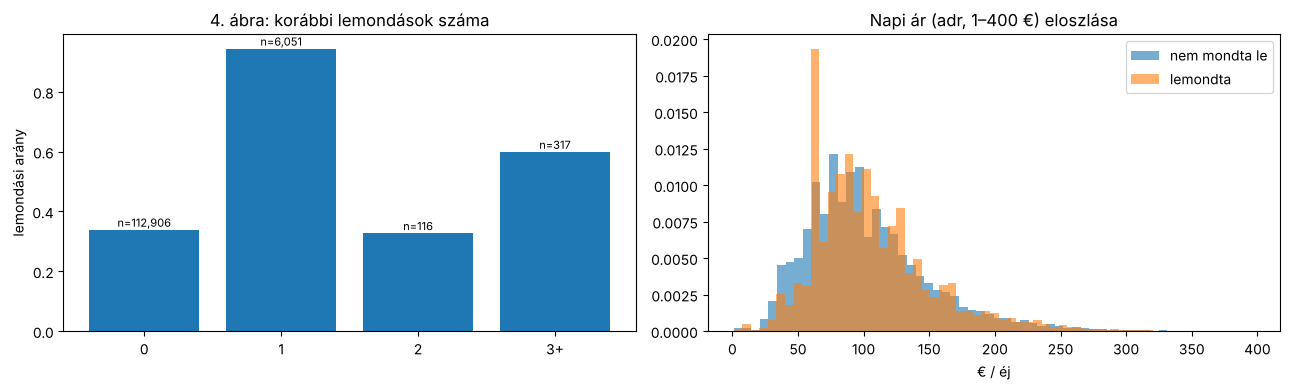

Medián napi ár: lemondott 96.2 | nem lemondott 92.5


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pc = df.groupby(df["previous_cancellations"].clip(upper=3))["is_canceled"].agg(["mean", "size"])
ax[0].bar(["0", "1", "2", "3+"], pc["mean"]); ax[0].set(title="4. ábra: korábbi lemondások száma", ylabel="lemondási arány")
for i, (k, r) in enumerate(pc.iterrows()):
    ax[0].text(i, r["mean"] + 0.01, f"n={int(r['size']):,}", ha="center", fontsize=8)
for lab, name in [(0, "nem mondta le"), (1, "lemondta")]:
    s = df.loc[(df["is_canceled"] == lab) & df["adr"].between(1, 400), "adr"]
    ax[1].hist(s, bins=60, alpha=0.6, density=True, label=name)
ax[1].set(title="Napi ár (adr, 1–400 €) eloszlása", xlabel="€ / éj"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Medián napi ár: lemondott", df.loc[df.is_canceled == 1, "adr"].median(), "| nem lemondott", df.loc[df.is_canceled == 0, "adr"].median())

**4. ábra, előzmények és ár:**
- **Korábbi lemondások:** egy korábbi lemondás után **94,4%** a lemondási arány, 0 korábbi lemondásnál 33,9%. Kettőnél viszont csak 32,8%, ami nem monoton. Az 1 korábbi lemondással rendelkező sorok 83%-a duplikátum, és 54%-uk csoportos foglalás: valószínűleg ugyanaz a csoport-hatás torzít, mint az előlegnél.
- **Napi ár:** a lemondott foglalások ára kicsit magasabb (medián 96,2 € vs. 92,5 €), de az eloszlások nagyon átfednek. Az ár önmagában gyenge jel, valószínűleg a szezonnal és a szobatípussal együtt számít.

## Szivárgás: mit NEM szabad használni?

Az órai kérdés: **ismerném ezt az értéket a jóslás pillanatában**, vagyis a foglaláskor?

In [8]:
# Mely oszlopokat NEM használhatjuk, mert a lemondás után / érkezéskor derülnek ki?
display(pd.crosstab(df["reservation_status"], df["is_canceled"]))
room = df["reserved_room_type"] != df["assigned_room_type"]
print(f"A kiosztott szoba eltér a foglalttól: {room.mean():.1%} — lemondási arány {df.loc[room, 'is_canceled'].mean():.1%}, "
      f"egyezésnél {df.loc[~room, 'is_canceled'].mean():.1%}")
top = df["country"].value_counts().head(6).index
display(rate("country").loc[top].T)
bc = df.groupby(df["booking_changes"].clip(upper=3))["is_canceled"].mean().round(3)
print("Lemondási arány a módosítások száma szerint (0, 1, 2, 3+):", bc.tolist())

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


A kiosztott szoba eltér a foglalttól: 12.5% — lemondási arány 5.4%, egyezésnél 41.6%


country,PRT,GBR,FRA,ESP,DEU,ITA
arány,0.566,0.202,0.186,0.254,0.167,0.354
db,48590.000,12129.000,10415.000,8568.000,7287.000,3766.000


Lemondási arány a módosítások száma szerint (0, 1, 2, 3+): [0.409, 0.142, 0.201, 0.166]


**Biztos szivárgás, ezeket kizárom:**
- **`reservation_status`:** a „Canceled” és a „No-Show” mindig lemondás, a „Check-Out” soha. Ez maga a válasz. A `reservation_status_date` ugyanígy a kimenet dátuma.

**Erősen gyanús, ezeket sem használom a fő modellben:**
- **`assigned_room_type`:** ha a kiosztott szoba eltér a foglalttól (a foglalások 12,5%-ánál), a lemondási arány csak **5,4%**, egyezésnél 41,6%. A szobát **érkezéskor** osztják ki, tehát akinek „más szobát adtak”, az nagyrészt meg is érkezett.
- **`country`:** a portugál foglalások **56,6%-át** mondják le, a többi nagy országnál ez 17–35%. Gyanítom, hogy az állampolgárságot sokszor csak a bejelentkezéskor rögzítik, így a lemondott foglalások a „PRT” alapértéken maradnak. Ezt az adatsor cikke nem tisztázza egyértelműen.
- **`booking_changes`:** a lemondási arány 0 módosításnál 40,9%, 1 módosításnál csak 14,2%. Módosítás a foglalás után, akár érkezéskor is történhet.
- **Továbbá:** a parkolóhelyet kérők közül **senki** nem mondta le a foglalását (0,0%). Ez is arra utal, hogy a parkolóigényt gyakran érkezéskor rögzítik. A végső projektben megvizsgálom.

## Első próba: magyarázzák-e a változók a célt?

Nem végleges modell, csak a harmadik kritérium ellenőrzése: **időrendi vágás** (tanító: 2017 áprilisáig, teszt: 2017 május–augusztus), hangolás nélkül, két modellel. Mutató: PR-AUC (mennyire kerülnek előre a lemondók a sorrendben) és ROC-AUC.

In [9]:
# Első próba: időrendi vágás (az utolsó 4 hónap a teszt), hangolás nélkül. Csak a magyarázóerő ellenőrzése.
tr, te = df[df["arrival_date"] < "2017-05-01"], df[df["arrival_date"] >= "2017-05-01"]
print(f"Tanító: {len(tr):,} foglalás (–2017-04) | Teszt: {len(te):,} (2017-05 – 2017-08), lemondási arány {te['is_canceled'].mean():.1%}")

CAT = ["hotel", "meal", "market_segment", "distribution_channel", "reserved_room_type", "deposit_type", "customer_type",
       "arrival_date_month"]
NUM = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies", "is_repeated_guest",
       "previous_cancellations", "previous_bookings_not_canceled", "days_in_waiting_list", "adr",
       "required_car_parking_spaces", "total_of_special_requests"]
SUSPECT_CAT, SUSPECT_NUM = ["assigned_room_type", "country"], ["booking_changes"]

def fit_eval(cat, num):
    X = lambda t: t[cat + num].fillna({"children": 0, "country": "ismeretlen"})
    out = {}
    for name, model, scale in [("Logisztikus", LogisticRegression(max_iter=3000), True),
                               ("XGBoost", XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                                                         colsample_bytree=0.8, n_jobs=-1, random_state=SEED), False)]:
        ct = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat),
                                ("n", StandardScaler() if scale else "passthrough", num)])
        p = make_pipeline(ct, model).fit(X(tr), tr["is_canceled"]).predict_proba(X(te))[:, 1]
        out[name] = {"PR-AUC": average_precision_score(te["is_canceled"], p), "ROC-AUC": roc_auc_score(te["is_canceled"], p)}
    return out

res = {"Arány (dummy)": {"PR-AUC": te["is_canceled"].mean(), "ROC-AUC": 0.5}}
for k, v in fit_eval(CAT, NUM).items(): res[k + " — megengedett jellemzők"] = v
for k, v in fit_eval(CAT + SUSPECT_CAT, NUM + SUSPECT_NUM).items(): res[k + " — + gyanús jellemzők"] = v
pd.DataFrame(res).T.round(3)

Tanító: 97,192 foglalás (–2017-04) | Teszt: 22,198 (2017-05 – 2017-08), lemondási arány 40.5%


,PR-AUC,ROC-AUC
Arány (dummy),0.405,0.500
Logisztikus — megengedett jellemzők,0.779,0.805
XGBoost — megengedett jellemzők,0.793,0.829
Logisztikus — + gyanús jellemzők,0.820,0.855
XGBoost — + gyanús jellemzők,0.830,0.871


**Eredmény:**
- **A magyarázó változók egyértelműen magyaráznak:** a dummy PR-AUC-ja 0,405 (a teszt lemondási aránya), a **logisztikus regresszióé 0,779**, az **XGBoosté 0,793** (ROC-AUC 0,829), csak a foglaláskor ismert jellemzőkből.
- **Az XGBoost előnye itt kicsi** (0,014). A végső projekt egyik kérdése, hogy jó jellemzőkkel (pl. összes éjszaka, ár per fő, a foglalás napja) ez a különbség nő-e, vagy a lineáris modell is elég.
- **A gyanús oszlopokkal** a PR-AUC 0,820-ra (logisztikus), illetve **0,830**-ra (XGBoost) „javul”. Ez az órán látott **„túl jó szám”**: a javulás egy része abból jön, hogy ezek az oszlopok a kimenetről árulkodnak.

## Következő lépések a végső projektben

1. **Tisztítás:** a furcsa értékek (0 vendég, 0 vagy negatív ár, 5 400 €) kezelése; a `Non Refund` / csoportos foglalások kérdésének eldöntése.
2. **Vágás:** időrendi zárolt teszt, és a CV-foldok úgy, hogy egy csoport (azonos sorok) ne szakadjon szét.
3. **Modellek:** dummy, logisztikus, fa, Random Forest, XGBoost, ugyanazokon a foldokon; mutatók: PR-AUC, kiegyensúlyozott pontosság, kalibráció.
4. **Visszacsatolás:** diagnosztika (szállodánként, szegmensenként, időben), és ebből új jellemzők, páros különbséggel mérve.
5. **Üzleti döntés:** túlfoglalási küszöb **költségek alapján** (üresen maradt szoba vs. áthelyezett vendég), nem csak egy rögzített kapacitással.

**Kérdések, amelyekre visszajelzést kérek:**
- A `Non Refund` / csoportos kontingensek: külön kezeljem vagy hagyjam ki?
- Az ország és a parkolóhely szivárgás-gyanúja elég erős-e ahhoz, hogy kihagyjam őket?
- Elég-e egy modell a két szállodára, vagy érdemes külön modellt építeni?